# Fixed-demand experiment


In [1]:
import numpy as np
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

In [2]:
# Problem setup

cost_type = 'piecewise'

d = 1.5

#T_range = np.linspace(100, 100000, 20).astype(int)
T_range = np.arange(2,36,2)
num_instances = 10

### Piecewise quadratic cost

We consider a single supplier with a smooth, piecewise quadratic cost function parameterized as follows:

$$
C(x) = 
\begin{cases}
\alpha x^2 + 10\alpha x & \text{if } 0 \le x < 1; \\
2\alpha x^2 + 8\alpha x + \alpha & \text{if } 1 \le x < 2; \\
4\alpha x^2 + 9 \alpha & \text{if } 2 \le x < 4.
\end{cases}
$$

Then, the supply function at price $p$ is
$$
x^\star(p) = 
\begin{cases}
0 & \text{if } 0 \le p < 10\alpha; \\
\frac{p-10\alpha}{2\alpha} & \text{if } 10\alpha \le p < 12\alpha; \\
\frac{p-8\alpha}{4\alpha} & \text{if } 12\alpha \le p < 16\alpha; \\
\frac{p}{8\alpha} & \text{otherwise}.
\end{cases}
$$

In [3]:
def sample_param_piecewise(rng):
    return rng.uniform(1/128, 1/32)

@njit
def reported_cost_piecewise(x, a):
    if x < 1:
        return a * x**2 + 10*a * x
    elif x < 2:
        return 2*a * x**2 + 8*a * x + a
    else:
        return 4*a * x**2 + 9*a

@njit
def supply_from_price_piecewise(price, a):
    if price < 10*a:
        return 0
    elif price < 12*a:
        return (price - 10*a) / (2*a)
    elif price < 16*a:
        return (price - 8*a) / (4*a)
    else:
        return price / (8*a)

@njit
def optimal_price_piecewise(d, a):
    if d < 1:
        return 2*a * d + 10*a
    elif d < 2:
        return 4*a * d + 8*a
    else:
        return 8*a * d

### Quadratic cost, three suppliers

We consider three suppliers, where the $i$th supplier ($i \in \{1, 2, 3\}$) has a cost function

$$C_i(x) = \alpha_i x^2.$$

Then, the suppliers' supply at price $p$ is

$$ x^*_i(p) = \frac{p}{2\alpha_i}. $$

We sample the cost of each supplier indpendently with $\alpha_i \sim \text{Unif}[1/8, 3/8]$.

In [4]:
def sample_param_multiple(rng):
    return rng.uniform(1/8, 3/8, size=(3,))

@njit
def reported_cost_multiple(x, a):
    u = x / np.sum(1/a)
    ix = u / a
    return np.sum(a * ix**2)

@njit
def supply_from_price_multiple(price, a):
    return price * np.sum(1/a) / 2

@njit
def optimal_price_multiple(d, a):
    return d * 2 / np.sum(1/a)

### Log-barrier-cost single-supplier setup

We consider a **single-supplier** setting using the scalar-parameterized log-barrier reported cost

$$
\hat C(x;\theta) = \theta \log\left(\frac{X}{X-x}\right), \qquad x < X.
$$

For a single supplier with capacity $X$ and parameter $\theta$, the supply at price $p$ is
$$
S(p;\theta)=X-\theta/p,
$$
and the demand-clearing price for a realized demand level $d<X$ is
$$
p^*(d)=\theta/(X-d).
$$


In [5]:
def sample_param_log(rng):
    return rng.uniform(0.5, 2.0)

X = 6.0            # must stay strictly above the largest scaled demand (4.0 here)
#assert X > d_max, 'Need X > d_max so the log cost is finite on the full demand support.'

@njit
def reported_cost_log(x, theta, eps=1e-10):
    x = max(0.0, min(x, X - eps))
    return theta * np.log(X / (X - x))

@njit
def supply_from_price_log(price, theta, eps=1e-10):
    price = max(float(price), eps)
    x = X - theta / price
    return max(0.0, min(x, X - eps))

@njit
def optimal_price_log(d, theta, eps=1e-10):
    d = max(0.0, min(d, X - eps))
    return theta / (X - d)

In [6]:
if cost_type == 'piecewise':
    sample_param = sample_param_piecewise
    reported_cost = reported_cost_piecewise
    supply_from_price = supply_from_price_piecewise
    optimal_price = optimal_price_piecewise
elif cost_type == 'three':
    sample_param = sample_param_multiple
    reported_cost = reported_cost_multiple
    supply_from_price = supply_from_price_multiple
    optimal_price = optimal_price_multiple
elif cost_type == 'log':
    sample_param = sample_param_log
    reported_cost = reported_cost_log
    supply_from_price = supply_from_price_log
    optimal_price = optimal_price_log
else:
    raise ValueError('Unknown cost function type')

In [7]:
@njit
def regret_fixed_demand(T, param, d):
    lo, hi = 0., 1.

    unified_regret = 0.0
    payment_regret = 0.0
    cost_regret = 0.0
    unmet_demand_regret = 0.0

    p_star = optimal_price(d, param)
    cost_star = reported_cost(d, param)

    for t in range(T):
        p_val = (lo + hi) / 2
        supplied = supply_from_price(p_val, param)

        cost_regret += reported_cost(supplied, param) - cost_star
        unmet_demand_regret += max(d - supplied, 0.0)
        payment_regret += p_val * supplied - p_star * d
        unified_regret += abs(p_val - p_star)

        if supplied < d:
            lo = p_val
        else:
            hi = p_val

    return unified_regret, unmet_demand_regret, cost_regret, payment_regret

## Run the varying-demand experiment with real CAISO chronology plus local perturbations

This preserves the daily pattern in the 2025 sequence and adds smooth multiplicative noise around each hourly value, rather than resampling hours i.i.d.


In [8]:
def mean_and_ci(arr):
    mean = arr.mean(axis=0)
    sd = arr.std(axis=0, ddof=1)
    se = sd / np.sqrt(arr.shape[0])
    ci_low = mean - 1.96 * se
    ci_high = mean + 1.96 * se
    return mean, ci_low, ci_high

In [9]:
%%time
max_T = max(T_range)

unified_regret_trials = np.zeros((num_instances, len(T_range)))
unmet_demand_regret_trials = np.zeros((num_instances, len(T_range)))
cost_regret_trials = np.zeros((num_instances, len(T_range)))
payment_regret_trials = np.zeros((num_instances, len(T_range)))

rng = np.random.default_rng(0)

for trial in range(num_instances):
    param = sample_param(rng)

    for j, T in enumerate(T_range):

        unified_regret, unmet_demand_regret, cost_regret, payment_regret = regret_fixed_demand(T, param, d)

        unified_regret_trials[trial, j] = unified_regret
        unmet_demand_regret_trials[trial, j] = unmet_demand_regret
        cost_regret_trials[trial, j] = cost_regret
        payment_regret_trials[trial, j] = payment_regret

unified_regret_arr_full, unified_ci_low, unified_ci_high = mean_and_ci(unified_regret_trials)
unmet_demand_regret_arr_full, unmet_ci_low, unmet_ci_high = mean_and_ci(unmet_demand_regret_trials)
cost_regret_arr_full, cost_ci_low, cost_ci_high = mean_and_ci(cost_regret_trials)
payment_regret_arr_full, payment_ci_low, payment_ci_high = mean_and_ci(payment_regret_trials)

CPU times: user 558 ms, sys: 48 ms, total: 606 ms
Wall time: 675 ms


In [10]:
if cost_type == 'piecewise':
    plot_name = 'Piecewise quadratic cost, single supplier'
elif cost_type == 'three':
    plot_name = 'Quadratic cost, three suppliers'
elif cost_type == 'log':
    plot_name = 'Log-barrier cost, single supplier'
else:
    raise ValueError('Unknown cost function type')

In [11]:
figsize = (6, 4)
postfix = '_short'
plt.rcParams.update({'font.size': 11})

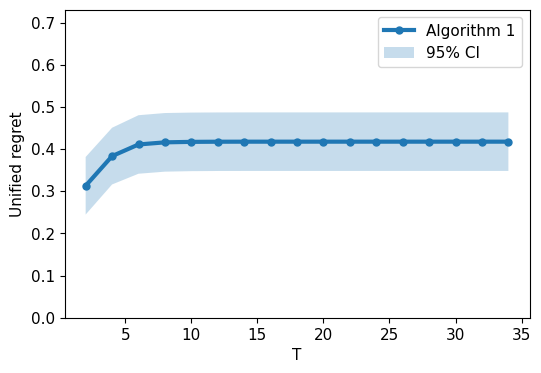

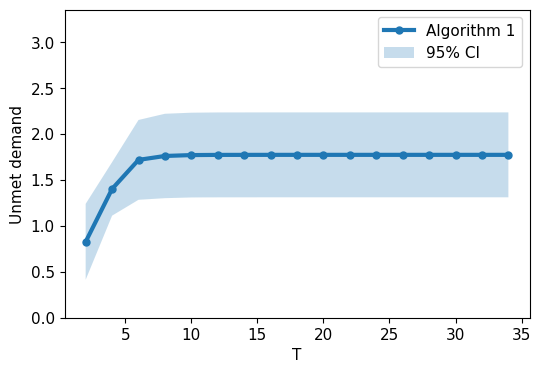

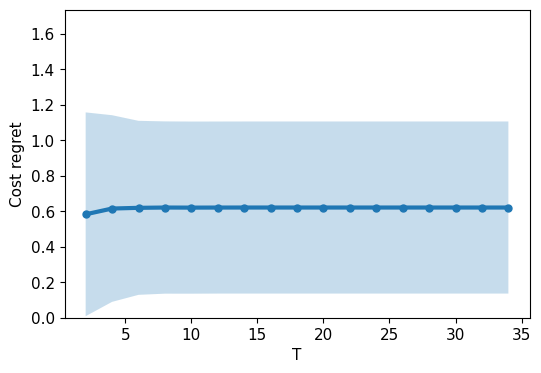

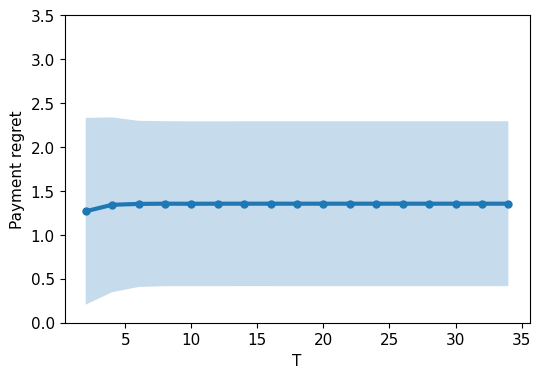

In [12]:
plt.figure(figsize=figsize)
plt.ylim([0, np.max(unified_ci_high) * 1.5])
plt.plot(T_range, unified_regret_arr_full, marker='o', markersize=5, linewidth=3, label='Algorithm 1')
plt.fill_between(T_range, unified_ci_low, unified_ci_high, alpha=0.25, label='95% CI')
plt.xlabel('T')
plt.ylabel('Unified regret')
plt.legend()
#plt.title(f'{plot_name}: unified regret')
plt.savefig(f'fixed_{cost_type}_unified{postfix}.pdf', bbox_inches='tight')
plt.show()

plt.figure(figsize=figsize)
plt.ylim([0, np.max(unmet_ci_high) * 1.5])
plt.plot(T_range, unmet_demand_regret_arr_full, marker='o', markersize=5, linewidth=3, label='Algorithm 1')
plt.fill_between(T_range, unmet_ci_low, unmet_ci_high, alpha=0.25, label='95% CI')
plt.xlabel('T')
plt.ylabel('Unmet demand')
#plt.title(f'{plot_name}: unmet demand')
plt.legend()
plt.savefig(f'fixed_{cost_type}_unmet_demand{postfix}.pdf', bbox_inches='tight')
plt.show()

plt.figure(figsize=figsize)
plt.ylim([0, np.max(cost_ci_high) * 1.5])
plt.plot(T_range, cost_regret_arr_full, marker='o', markersize=5, linewidth=3, label='Algorithm 1')
plt.fill_between(T_range, cost_ci_low, cost_ci_high, alpha=0.25, label='95% CI')
plt.xlabel('T')
plt.ylabel('Cost regret')
#plt.legend()
#plt.title(f'{plot_name}: cost regret')
plt.savefig(f'fixed_{cost_type}_cost_regret{postfix}.pdf', bbox_inches='tight')
plt.show()

plt.figure(figsize=figsize)
plt.ylim([0, np.max(payment_ci_high) * 1.5])
plt.plot(T_range, payment_regret_arr_full, marker='o', markersize=5, linewidth=3, label='Algorithm 1')
plt.fill_between(T_range, payment_ci_low, payment_ci_high, alpha=0.25, label='95% CI')
plt.xlabel('T')
plt.ylabel('Payment regret')
#plt.legend()
#plt.title(f'{plot_name}: payment regret')
plt.savefig(f'fixed_{cost_type}_payment_regret{postfix}.pdf', bbox_inches='tight')
plt.show()

In [13]:
unified_slope = stats.linregress(T_range, unified_regret_arr_full).slope
unmet_slope = stats.linregress(T_range, unmet_demand_regret_arr_full).slope
cost_slope = stats.linregress(T_range, np.abs(cost_regret_arr_full)).slope
payment_slope = stats.linregress(T_range, np.abs(payment_regret_arr_full)).slope

print('Unified regret slope:', unified_slope)
print('Unmet demand regret slope:', unmet_slope)
print('cost regret slope:', cost_slope)
print('Payment regret slope:', payment_slope)

Unified regret slope: 0.0013805749302948749
Unmet demand regret slope: 0.012962899262449005
cost regret slope: 0.00043777923715882465
Payment regret slope: 0.0009824554894842432
